# EDA  -  CFPB Consumer Complaints

- `data/complaints.csv`  -  current bulk export
- `data/archive/*.zip`  -  the FOIA narratives archive

Target: `Company response to consumer == "Closed with monetary relief"`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (8, 3.5)

DATA = Path("data/complaints.csv")
print(f"{DATA.stat().st_size / 1e9:.2f} GB")

5.47 GB


In [2]:
pd.read_csv(DATA, nrows=5)

,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2024-02-11,Credit reporting or other personal consumer re...,Credit reporting,Unable to get your credit report or credit score,Other problem getting your report or credit score,NaN,"EQUIFAX, INC.",FL,32828,NaN,Web,2024-02-11,Closed with explanation,Yes,8324610
1,2024-06-05,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account status incorrect,NaN,Experian Information Solutions Inc.,FL,32828,NaN,Web,2024-06-05,Closed with explanation,Yes,9186888
2,2024-06-05,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account status incorrect,Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",FL,32828,NaN,Web,2024-06-05,Closed with non-monetary relief,Yes,9186287
3,2024-06-05,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account status incorrect,NaN,"EQUIFAX, INC.",FL,32828,NaN,Web,2024-06-05,Closed with non-monetary relief,Yes,9189809
4,2024-06-05,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account status incorrect,Company has responded to the consumer and the ...,Experian Information Solutions Inc.,FL,32828,NaN,Web,2024-06-05,Closed with explanation,Yes,9189374


The file is 5.5 GB (~18M rows), so draw a 0.5% random sample (~90k rows) in one chunked pass and analyze that. The sample is cached to parquet, so this is only slow the first time.

In [3]:
SAMPLE = Path("data/complaints_sample.parquet")

if SAMPLE.exists():
    df = pd.read_parquet(SAMPLE)
else:
    pieces = [chunk.sample(frac=0.005, random_state=0)
              for chunk in pd.read_csv(DATA, chunksize=1_000_000, dtype=str)]
    df = pd.concat(pieces, ignore_index=True)
    df.to_parquet(SAMPLE, index=False)

df["Year"] = df["Date received"].str[:4].astype(int)
len(df)

90312

### Missingness

In [4]:
df.isna().mean().sort_values(ascending=False).round(3)

Tags                            0.954
Company public response         0.450
Sub-issue                       0.052
Sub-product                     0.013
State                           0.003
ZIP code                        0.000
Issue                           0.000
Product                         0.000
Company                         0.000
Date received                   0.000
Submitted via                   0.000
Date sent to company            0.000
Company response to consumer    0.000
Timely response?                0.000
Complaint ID                    0.000
Year                            0.000
dtype: float64

### Target imbalance

In [5]:
df["Company response to consumer"].value_counts()

Company response to consumer
Closed with explanation            55766
Closed with non-monetary relief    30055
In progress                         3037
Closed with monetary relief         1073
Untimely response                    187
Closed without relief                 92
Closed                                72
Closed with relief                    30
Name: count, dtype: int64

In [6]:
RELIEF = "Closed with monetary relief"
relief = df["Company response to consumer"] == RELIEF
print(f"Monetary relief rate: {relief.mean():.2%}")

Monetary relief rate: 1.19%


### Volume and outcomes over time

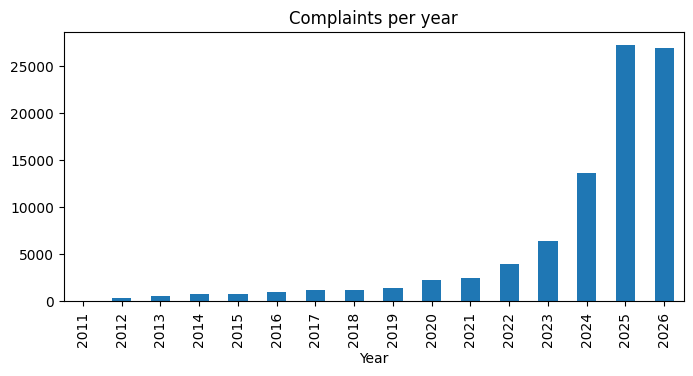

In [7]:
df["Year"].value_counts().sort_index().plot.bar(title="Complaints per year");

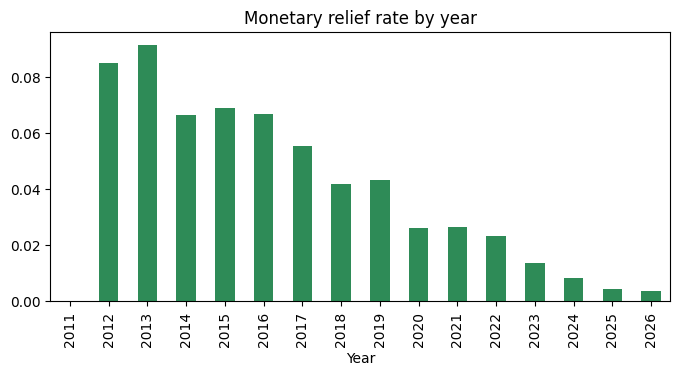

In [8]:
relief.groupby(df["Year"]).mean().plot.bar(title="Monetary relief rate by year", color="seagreen");

### Products

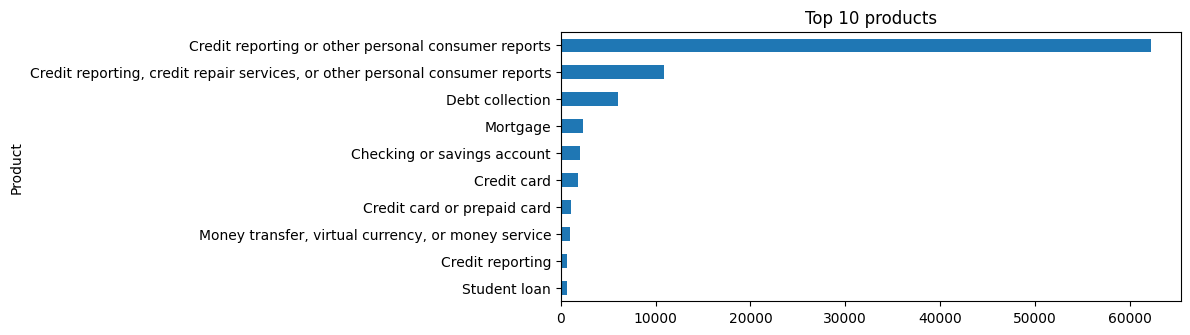

In [9]:
df["Product"].value_counts().head(10).iloc[::-1].plot.barh(title="Top 10 products");

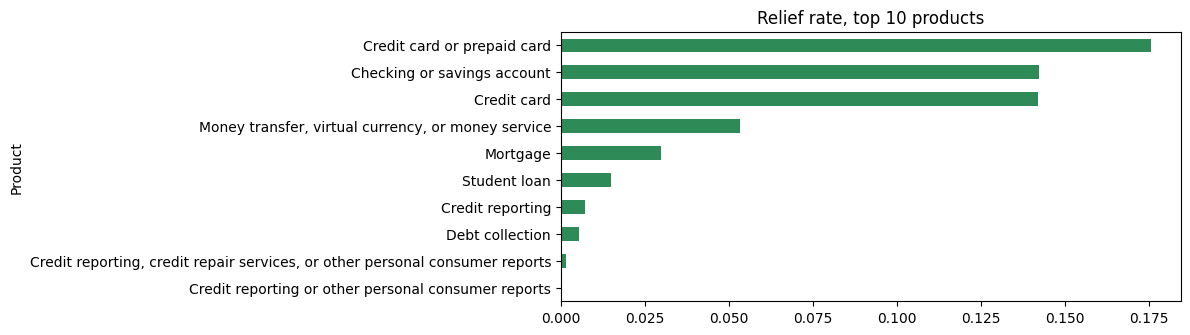

In [10]:
top10 = df["Product"].value_counts().head(10).index
relief[df["Product"].isin(top10)].groupby(df["Product"]).mean() \
    .sort_values().plot.barh(title="Relief rate, top 10 products", color="seagreen");

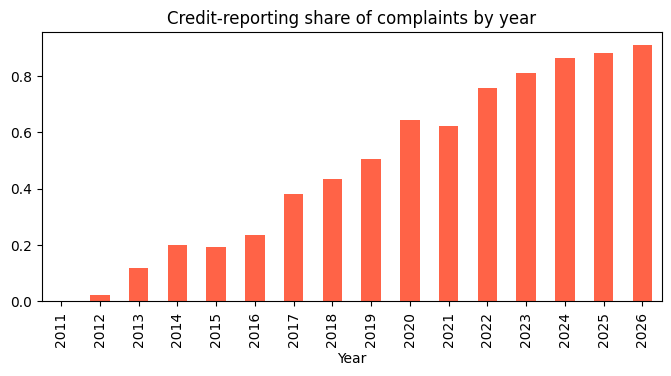

In [11]:
# Proposal flags the post-2023 credit reporting surge
df["Product"].str.contains("Credit reporting", case=False).groupby(df["Year"]).mean() \
    .plot.bar(title="Credit-reporting share of complaints by year", color="tomato");

### Companies and channels

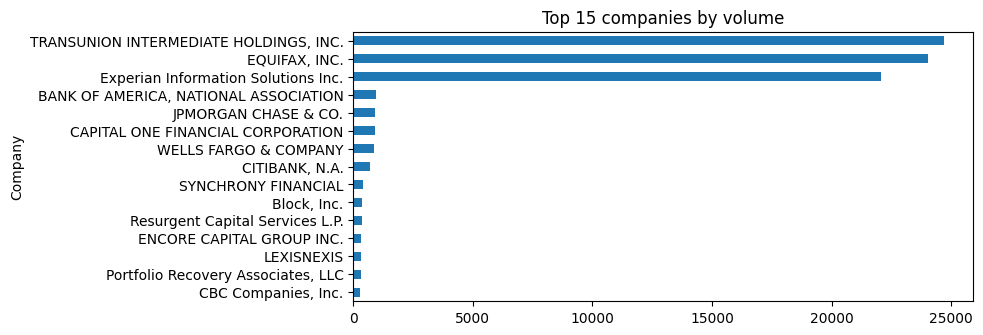

In [12]:
df["Company"].value_counts().head(15).iloc[::-1].plot.barh(title="Top 15 companies by volume");

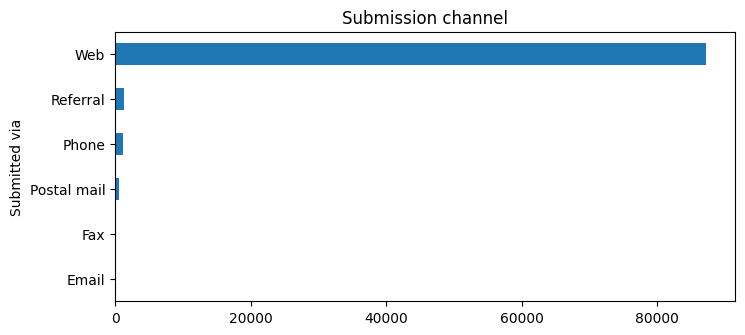

In [13]:
df["Submitted via"].value_counts().sort_values().plot.barh(title="Submission channel");

## Working dataset  -  complaints with narratives

The archive zips are full records including `Consumer complaint narrative` (published only for consumers who opted in  -  about 22% of rows). Reduce each export to its narrative rows and cache one parquet per export in `data/narratives/`. One-time cost; already-built files are skipped.

In [14]:
ARCHIVE = Path("data/archive")
NARR_DIR = Path("data/narratives")
NARR_DIR.mkdir(exist_ok=True)

for zp in sorted(ARCHIVE.glob("CCDB_Export_*.zip")):
    out = NARR_DIR / (zp.stem + ".parquet")
    if out.exists():
        continue
    parts = [chunk[chunk["Consumer complaint narrative"].notna()]
             for chunk in pd.read_csv(zp, dtype=str, chunksize=500_000)]
    pd.concat(parts, ignore_index=True).to_parquet(out, index=False)
    print(f"{out.name}: {sum(map(len, parts)):,} narrative rows")

print(f"{len(list(NARR_DIR.glob('*.parquet')))} parquet files ready")

21 parquet files ready


In [15]:
# Load the working dataset without the narrative text (metadata is light, text is ~4 GB)
meta_cols = ["Complaint ID", "Date received", "Product", "Sub-product", "Issue", "Company",
             "State", "Submitted via", "Company response to consumer", "Timely response?"]
narr = pd.read_parquet(NARR_DIR, columns=meta_cols)
narr["Year"] = narr["Date received"].str[:4].astype(int)
print(f"{len(narr):,} complaints with narratives")

3,851,415 complaints with narratives


### Reading some narratives

In [19]:
text = pd.read_parquet(NARR_DIR / "CCDB_Export_12_July_2025_through_August_2025.parquet",
                       columns=["Product", "Consumer complaint narrative"])

for product in text["Product"].value_counts().head(5).index:
    example = text.loc[text["Product"] == product, "Consumer complaint narrative"] \
                  .sample(1, random_state=7).iloc[0]
    print("=" * 90)
    print(f"[{product}]")
    print(example[:700], "\n")

[Credit reporting or other personal consumer reports]
I am concerned about the validity and accuracy of your recent investigation of these accounts that are reporting on my credit report. Last month I requested an investigation because I felt the item was not being reported legally. Couple of days ago I received a letter stating that you have ceased investigation of my credit reports because, in your opinion, you believe that I have used a third party credit repair agency. Not only do I believe this to be a stall tactic on your part to grant you an additional 30 days to comply with my original request, but I believe it to be a blatant violation of the FCRA. 

I have attached a copy of my government issued ID as well as mail showing proof of add 

[Debt collection]
My credit report shows collection accounts that I believe include inaccurate information. Under my rights as outlined in 15 USC 1681e ( b ) and 15 USC 1681i, I am entitled to a fully accurate report. I am asking for a review 

In [ ]:
# the products where monetary relief actually happens
bank_card = pd.read_parquet(NARR_DIR / "CCDB_Export_12_July_2025_through_August_2025.parquet",
                            columns=["Product", "Company response to consumer", "Consumer complaint narrative"])
bank_card = bank_card[bank_card["Product"].isin(["Checking or savings account", "Credit card", "Prepaid card"])]

for _, row in bank_card.sample(6, random_state=3).iterrows():
    print("=" * 90)
    print(f"[{row['Product']}]  ->  {row['Company response to consumer']}")
    print(row["Consumer complaint narrative"][:800], "\n")

[Prepaid card]  ->  Closed with explanation
I have called the card distributor multiple times only to be hung up every time. Wont even go to a live person and wont accept the card information that I provide. 

[Credit card]  ->  Closed with explanation
Call the company and ask for the information. And they said that the signature was done electronically. They said to file a police report. I tried to do that, and they said that the statute of limitations had ended that I would need to get an IC3 report and also a federal fraud report. I have gotten the IC3 report and now needing a federal fraud report for them to take it off my credit. 

[Credit card]  ->  Closed with non-monetary relief
On XX/XX/year> I received multiple emails entailing that I had opened a new credit card with CapitalOne for a limit of {$20000.00}. I proceeded to call CapitalOne and explain that this was not my doing. They have flagged the account as fraudulent, and I froze my credit through Experian. 

[Credit card] 

In [ ]:
# bank/card complaints that ended in monetary relief
winners = bank_card[bank_card["Company response to consumer"] == RELIEF]
print(f"{len(winners):,} of {len(bank_card):,} bank/card complaints in this export got monetary relief\n")

for _, row in winners.sample(6, random_state=3).iterrows():
    print("=" * 90)
    print(f"[{row['Product']}]")
    print(row["Consumer complaint narrative"][:800], "\n")

2,265 of 16,222 bank/card complaints in this export got monetary relief

[Credit card]
Hi, I had taken XXXX credit of {$6000.00}, from my dentist office to pay for dentures. They had misleading information on their promotional APR. I had been paying on time for XXXX  years with no issues. I had {$2000.00} remaining balance as of XX/XX/XXXX. They charged me {$3500.00} in interest, due to not paying it off fully during the promotional period. This is deeply concerning and misleading interest scam. How can they charge me more than what I Owe at that time. Only explanation with customer service they had XX/XX/XXXX is that why didnt I check the statement on XX/XX/XXXX, where they gave warning. After speaking to representative ( XXXX XXXX ), who basically told me that if I pay of the remaining balance of {$2000.00}, this inane credit interest will be waived. He did the transaction 

[Checking or savings account]
On XX/XX/year> on my way to work I stopped by Capital One to deposit {$500.00} i

### Text properties that will need handling

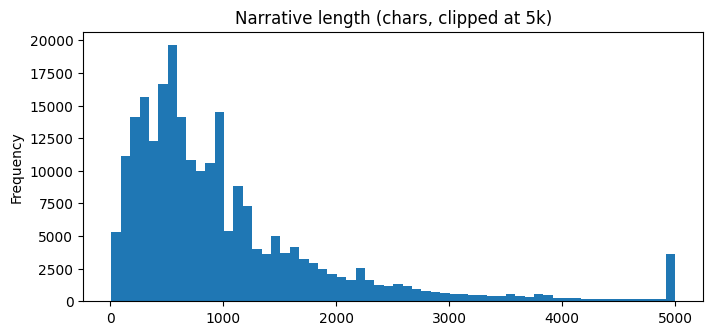

In [22]:
text["Consumer complaint narrative"].str.len().clip(upper=5000) \
    .plot.hist(bins=60, title="Narrative length (chars, clipped at 5k)");

In [23]:
# PII is masked with XXXX tokens (names, dates, amounts)
redacted = text["Consumer complaint narrative"].str.contains("XXXX", regex=False)
print(f"Narratives containing XXXX redaction tokens: {redacted.mean():.0%}")

Narratives containing XXXX redaction tokens: 56%


In [24]:
# Templated boilerplate: exact-duplicate narratives filed many times
dupes = text["Consumer complaint narrative"].value_counts()
repeated = dupes[dupes > 1]
print(f"{len(repeated):,} distinct texts appear more than once, covering {repeated.sum():,} "
      f"of {len(text):,} complaints ({repeated.sum() / len(text):.0%})\n")
print(f"Most repeated narrative ({dupes.iloc[0]:,} times):\n")
print(dupes.index[0][:500])

21,281 distinct texts appear more than once, covering 136,272 of 234,404 complaints (58%)

Most repeated narrative (5,068 times):

You have reported inaccurate and unauthorized accounts on my credit report, which is a violation of the Fair Credit Reporting Act ( 15 U.S. Code 1681i ) requiring a proper reinvestigation of disputed items, and 1681e ( b ), which mandates maximum possible accuracy. These false entries are damaging and unjust, especially since Ive never opened or authorized these accounts. If you fail to investigate and correct this, I may pursue legal action under the FCRA and FDCPA ( 15 U.S. Code 1692e ) for de
